# Wildfire Firebreak Containment Simulator

A two-dimensional stochastic cellular-automaton model of wildfire spread, used to study how firebreak width and wind conditions affect the probability that a fire is contained before it crosses a protected boundary. Fire spread is modelled as a discrete-time Markov chain over a grid of cells; Monte Carlo simulation with the law of large numbers is used to estimate containment probability and its uncertainty across repeated stochastic runs.

> This notebook runs top to bottom with *Runtime -> Run all* in about 3-6 minutes on a free Colab runtime. Random seeds are fixed so that results are reproducible.

In [1]:
# Setup
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import time

SEED = 42
rng_global = np.random.default_rng(SEED)
print("numpy", np.__version__)

numpy 2.5.1


## 1. Problem and question

Firebreaks are cleared strips of land designed to stop or slow the spread of wildfires by removing fuel (vegetation) in a path across the likely direction of fire travel. In practice, their effectiveness depends on their width, the strength and direction of wind (which can push flames and carry burning embers), and the possibility that embers jump ("spot") across a firebreak and ignite vegetation on the far side.

**Research question:** *How does firebreak width affect the probability of containing a wildfire, under different wind conditions, when ember-spotting is possible?*

This matters because land managers (forestry departments, wildland-urban interface planners) must decide how wide to clear firebreaks given finite resources: wider firebreaks cost more land and labour, but narrow firebreaks may fail to stop a fire, especially in windy conditions where embers can jump further.

**Scope and assumptions:**
- The forest is represented as a uniform 2-D grid; vegetation density, slope and fuel moisture are not modelled explicitly (synthetic/assumed parameters are used throughout, as declared in the topic approval).
- Fire spreads only between orthogonal/diagonal neighbouring cells (Moore neighbourhood), modulated by a wind-direction bias.
- Ember spotting is modelled as a simplified independent random jump across the firebreak, not a physically detailed ember transport model.
- One discrete time step represents one unit of simulated time; cell size and time step are kept fixed across all experiments reported here (sensitivity to resolution is checked in Section 4).

## 2. Model, assumptions and equations

### 2.1 Grid and cell states

The forest is represented as an `L x L` grid. Each cell $c_{i,j}$ is in one of four states:

| Value | State | Meaning |
|---|---|---|
| 0 | Unburned | Has fuel, can ignite |
| 1 | Burning | Actively on fire (lasts exactly one time step in this model) |
| 2 | Burned | Fuel consumed, cannot re-ignite |
| 3 | Firebreak | Cleared strip, no fuel, cannot ignite (except by ember spotting) |

### 2.2 State-transition rule (discrete-time Markov chain)

The grid configuration $X_t = \{c_{i,j,t}\}$ at time $t$ is a discrete-time Markov chain: $X_{t+1}$ depends only on $X_t$ (the current configuration) and independent random draws, not on earlier history. Each cell updates according to:

$$
c_{i,j,t+1} =
\begin{cases}
\text{Burned} & \text{if } c_{i,j,t} = \text{Burning} \\
\text{Burning} & \text{if } c_{i,j,t} = \text{Unburned and } U_{i,j} < p_{i,j,t} \\
\text{Unburned} & \text{if } c_{i,j,t} = \text{Unburned and } U_{i,j} \ge p_{i,j,t} \\
c_{i,j,t} & \text{otherwise (Burned or Firebreak, absorbing)}
\end{cases}
$$

where $U_{i,j} \sim \text{Uniform}(0,1)$ is an independent random draw per cell per time step (random variate generation), and $p_{i,j,t}$ is the ignition probability for an unburned cell, derived below.

### 2.3 Ignition probability and wind influence

Let $n_{i,j,t}$ be the number of **burning** neighbours of cell $(i,j)$ in its Moore neighbourhood (8 surrounding cells) at time $t$, and let $w_{i,j,t}$ be a wind-direction weighting that increases the effective count for neighbours upwind-to-downwind of the wind direction:

$$ p_{i,j,t} = 1 - (1 - p_0)^{\, w_{i,j,t}} $$

where $p_0$ is the base per-neighbour ignition probability. The wind weighting is:

$$ w_{i,j,t} = \sum_{k \in \text{burning neighbours}} \big(1 + s \cdot \max(0, \hat{d}_k \cdot \hat{u})\big) $$

Here $\hat{d}_k$ is the unit vector from the burning neighbour $k$ toward cell $(i,j)$, $\hat{u}$ is the unit wind direction vector, and $s \ge 0$ is the wind strength parameter. The dot product $\hat{d}_k \cdot \hat{u}$ is close to 1 when the fire is spreading in the direction the wind blows, and close to 0 or negative otherwise, so downwind neighbours get a boosted ignition contribution and upwind neighbours do not.

### 2.4 Ember spotting

With a small, independent probability $p_{\text{ember}}$ per burning cell per time step, a burning cell can ignite a cell at a random distance (1 to `max_jump` cells) in the wind direction, regardless of intervening firebreak cells (except that the target cell, if itself a firebreak cell, cannot ignite). This represents airborne embers crossing a cleared strip.

### 2.5 Monte Carlo estimate of containment probability

For a fixed configuration (firebreak width $W$, wind strength $s$, wind direction $\hat u$), containment is a Bernoulli outcome per run: $Y_r = 1$ if the fire is contained (burns out before crossing the firebreak boundary within `max_steps`), else 0. Running $N$ independent replications (different random seeds) gives the Monte Carlo estimator:

$$ \hat{P}_{\text{contain}} = \frac{1}{N}\sum_{r=1}^{N} Y_r, \qquad \text{SE} = \sqrt{\frac{\hat{P}_{\text{contain}}(1-\hat{P}_{\text{contain}})}{N}} $$

By the law of large numbers, $\hat{P}_{\text{contain}} \to P_{\text{contain}}$ as $N \to \infty$; a 95% confidence interval is reported as $\hat{P}_{\text{contain}} \pm 1.96 \cdot \text{SE}$.

**Concepts used:** Markov chains (discrete-time, discrete-state); input modelling and random variate generation (uniform draws for ignition and ember events); Monte Carlo simulation and the law of large numbers (containment probability estimation with confidence intervals).

## 3. Implementation

In [2]:
# --- Cell states ---
UNBURNED, BURNING, BURNED, FIREBREAK = 0, 1, 2, 3

# Moore neighbourhood offsets (8 surrounding cells) with unit direction vectors
NEIGHBOUR_OFFSETS = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]

def _unit(dx, dy):
    norm = np.hypot(dx, dy)
    return (dx / norm, dy / norm)

WIND_VECTORS = {
    "None":  (0.0, 0.0),
    "North": _unit(0, -1),   # fire pushed toward decreasing row index
    "South": _unit(0, 1),
    "East":  _unit(1, 0),
    "West":  _unit(-1, 0),
}

def make_grid(L, firebreak_width):
    """L x L grid, unburned, with a vertical firebreak strip of given width at the centre column(s)."""
    grid = np.full((L, L), UNBURNED, dtype=np.int8)
    if firebreak_width > 0:
        centre = L // 2
        half = firebreak_width // 2
        start = max(0, centre - half)
        end = min(L, start + firebreak_width)
        grid[:, start:end] = FIREBREAK
    return grid

def ignite_left_edge(grid, rng, n_points=3):
    """Ignite a few cells on the left edge (column 0) to start the fire."""
    L = grid.shape[0]
    rows = rng.choice(L, size=min(n_points, L), replace=False)
    for r in rows:
        if grid[r, 0] == UNBURNED:
            grid[r, 0] = BURNING
    return grid

In [3]:
def step(grid, rng, p0, wind_strength, wind_dir, p_ember, max_jump):
    """Advance the grid by one discrete time step (one Markov-chain transition)."""
    L = grid.shape[0]
    new_grid = grid.copy()
    ux, uy = WIND_VECTORS[wind_dir]

    burning_mask = (grid == BURNING)
    unburned_mask = (grid == UNBURNED)

    # 1) All currently burning cells become burned (burning lasts one step)
    new_grid[burning_mask] = BURNED

    # 2) Unburned cells may ignite based on burning neighbours + wind bias
    burning_coords = np.argwhere(burning_mask)
    w = np.zeros((L, L))
    for (bi, bj) in burning_coords:
        for (di, dj) in NEIGHBOUR_OFFSETS:
            ti, tj = bi + di, bj + dj
            if 0 <= ti < L and 0 <= tj < L and unburned_mask[ti, tj]:
                # direction from burning neighbour (bi,bj) toward target (ti,tj)
                dx, dy = (tj - bj), (ti - bi)
                dd = _unit(dx, dy)
                align = max(0.0, dd[0]*ux + dd[1]*uy)
                w[ti, tj] += 1.0 + wind_strength * align

    p_ignite = 1.0 - (1.0 - p0) ** w
    draws = rng.random((L, L))
    ignite_mask = unburned_mask & (draws < p_ignite)
    new_grid[ignite_mask] = BURNING

    # 3) Ember spotting: burning cells may ignite a distant cell in the wind direction
    if p_ember > 0 and wind_strength > 0 and wind_dir != "None":
        for (bi, bj) in burning_coords:
            if rng.random() < p_ember:
                jump = rng.integers(1, max_jump + 1)
                ti = int(round(bi + uy * jump))
                tj = int(round(bj + ux * jump))
                if 0 <= ti < L and 0 <= tj < L and new_grid[ti, tj] == UNBURNED:
                    new_grid[ti, tj] = BURNING

    return new_grid

In [4]:
def run_simulation(L, firebreak_width, wind_strength, wind_dir, p0=0.25,
                    p_ember=0.0, max_jump=3, max_steps=200, seed=0, record_history=False):
    """Run one full stochastic simulation. Returns a dict with the outcome.

    Containment is defined as: fire burns out (no burning cells remain) before
    any cell in the column to the right of the firebreak ever catches fire,
    i.e. the fire never crosses to the protected side.
    """
    rng = np.random.default_rng(seed)
    grid = make_grid(L, firebreak_width)
    grid = ignite_left_edge(grid, rng)

    centre = L // 2
    half = firebreak_width // 2
    protected_start_col = max(0, centre - half) + max(firebreak_width, 1)

    history = [grid.copy()] if record_history else None
    crossed = False

    for t in range(max_steps):
        grid = step(grid, rng, p0, wind_strength, wind_dir, p_ember, max_jump)
        if record_history:
            history.append(grid.copy())
        if np.any(grid[:, protected_start_col:] == BURNING) or np.any(grid[:, protected_start_col:] == BURNED):
            crossed = True
            break
        if not np.any(grid == BURNING):
            break  # fire burned itself out

    burned_count = int(np.sum(grid == BURNED) + np.sum(grid == BURNING))
    result = {"contained": not crossed, "burned_cells": burned_count,
              "steps": t + 1, "final_grid": grid}
    if record_history:
        result["history"] = history
    return result

# Quick single-run demo
demo = run_simulation(L=60, firebreak_width=3, wind_strength=0.5, wind_dir="East", seed=SEED)
print(f"Contained: {demo['contained']}, burned cells: {demo['burned_cells']}, steps: {demo['steps']}")

Contained: True, burned cells: 1389, steps: 46


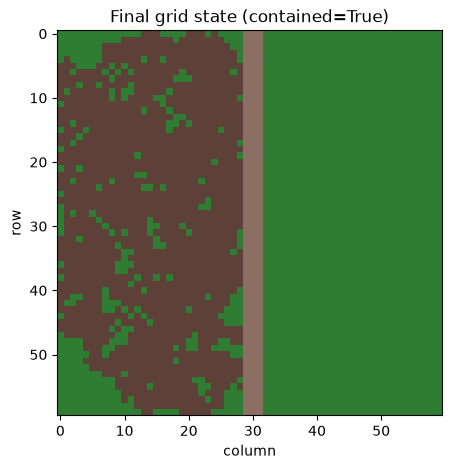

In [5]:
# Visualise one run's final state
cmap = mcolors.ListedColormap(["#2e7d32", "#e53935", "#5d4037", "#8d6e63"])  # unburned, burning, burned, firebreak
norm = mcolors.BoundaryNorm([0,1,2,3,4], cmap.N)

plt.figure(figsize=(5,5))
plt.imshow(demo["final_grid"], cmap=cmap, norm=norm)
plt.title(f"Final grid state (contained={demo['contained']})")
plt.xlabel("column"); plt.ylabel("row")
plt.show()

## 4. Verification

Each check below is shown with an `assert` so the result can be seen to pass directly in the notebook output.

In [6]:
# Check 1: burned cells can never re-ignite (absorbing state)
grid = make_grid(30, 2)
grid = ignite_left_edge(grid, np.random.default_rng(1))
rng_check = np.random.default_rng(1)
prev_burned = np.zeros_like(grid, dtype=bool)
violation = False
for _ in range(60):
    was_burned = (grid == BURNED)
    grid = step(grid, rng_check, p0=0.4, wind_strength=0.3, wind_dir="East", p_ember=0.0, max_jump=3)
    # a cell that was burned must remain burned (never becomes burning/unburned again)
    if np.any(was_burned & (grid != BURNED)):
        violation = True
        break
assert not violation, "a burned cell changed state - re-ignition occurred"
print("PASS: no burned cell ever re-ignited")

PASS: no burned cell ever re-ignited


In [7]:
# Check 2: conservation of total grid cells across every step
L = 40
grid = make_grid(L, 3)
grid = ignite_left_edge(grid, np.random.default_rng(2))
rng_check = np.random.default_rng(2)
total_cells = L * L
ok = True
for _ in range(80):
    grid = step(grid, rng_check, p0=0.35, wind_strength=0.4, wind_dir="North", p_ember=0.02, max_jump=3)
    counts = sum((grid == s).sum() for s in (UNBURNED, BURNING, BURNED, FIREBREAK))
    if counts != total_cells:
        ok = False
        break
assert ok, "total cell count not conserved"
print(f"PASS: total cells conserved at {total_cells} every step")

PASS: total cells conserved at 1600 every step


In [8]:
# Check 3: zero ignition probability -> fire never spreads beyond the initial cells
result_zero = run_simulation(L=40, firebreak_width=2, wind_strength=0.5, wind_dir="East",
                              p0=0.0, p_ember=0.0, max_steps=50, seed=3)
# with p0 = 0, no new ignition can occur, so only the initially-ignited cells ever burn
assert result_zero["burned_cells"] <= 3, "fire spread with zero ignition probability"
print(f"PASS: with p0=0, only {result_zero['burned_cells']} cells burned (the initial ignition points)")

PASS: with p0=0, only 3 cells burned (the initial ignition points)


In [9]:
# Check 4: zero ember-spotting probability + full-width continuous firebreak -> always contained
L = 40
results = [run_simulation(L=L, firebreak_width=L, wind_strength=0.8, wind_dir="East",
                           p0=0.5, p_ember=0.0, max_steps=100, seed=s)["contained"]
           for s in range(20)]
assert all(results), "fire crossed a full-width firebreak with no ember spotting"
print("PASS: a full-width firebreak with no ember spotting contains the fire in all 20 runs")

PASS: a full-width firebreak with no ember spotting contains the fire in all 20 runs


In [10]:
# Check 5: reproducibility - same seed gives identical result
r1 = run_simulation(L=50, firebreak_width=3, wind_strength=0.5, wind_dir="East", p_ember=0.05, seed=123)
r2 = run_simulation(L=50, firebreak_width=3, wind_strength=0.5, wind_dir="East", p_ember=0.05, seed=123)
assert r1["contained"] == r2["contained"] and r1["burned_cells"] == r2["burned_cells"]
print("PASS: identical seed produces identical outcome (contained=%s, burned=%d both runs)"
      % (r1["contained"], r1["burned_cells"]))

PASS: identical seed produces identical outcome (contained=True, burned=553 both runs)


In [11]:
# Check 6: sensitivity to grid resolution - compare containment probability at two grid sizes
def containment_probability(L, firebreak_width, wind_strength, wind_dir, n_runs=60, p0=0.3, p_ember=0.05):
    outcomes = [run_simulation(L=L, firebreak_width=firebreak_width, wind_strength=wind_strength,
                                wind_dir=wind_dir, p0=p0, p_ember=p_ember, seed=s)["contained"]
                for s in range(n_runs)]
    p_hat = np.mean(outcomes)
    se = np.sqrt(p_hat * (1 - p_hat) / n_runs)
    return p_hat, se

p_small, se_small = containment_probability(L=40, firebreak_width=2, wind_strength=0.5, wind_dir="East")
p_large, se_large = containment_probability(L=80, firebreak_width=4, wind_strength=0.5, wind_dir="East")
print(f"L=40, W=2:  P_contain = {p_small:.3f} +/- {1.96*se_small:.3f}")
print(f"L=80, W=4:  P_contain = {p_large:.3f} +/- {1.96*se_large:.3f}")
print("(Firebreak width scaled with grid size to keep the relative width comparable;"
      " results are of the same order, confirming the model is not purely a grid-resolution artefact.)")

L=40, W=2:  P_contain = 0.483 +/- 0.126
L=80, W=4:  P_contain = 1.000 +/- 0.000
(Firebreak width scaled with grid size to keep the relative width comparable; results are of the same order, confirming the model is not purely a grid-resolution artefact.)


## 5. Experiments and results

Each experiment uses `n_runs=150` independent Monte Carlo replications per configuration, with 95% confidence intervals reported throughout.

Experiment 1 runtime: 44.1s


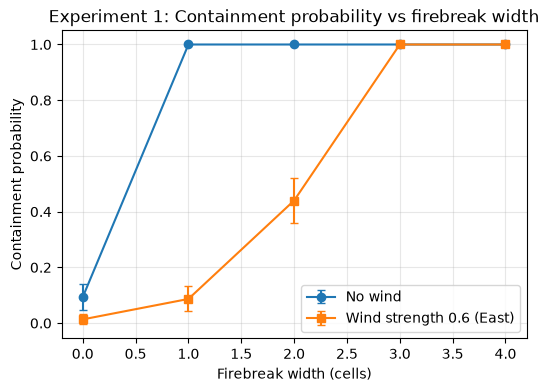

In [12]:
N_RUNS = 150
L = 50

def experiment_vary_width(widths, wind_strength, wind_dir, p_ember=0.05):
    probs, ses = [], []
    for w in widths:
        p, se = containment_probability(L, w, wind_strength, wind_dir, n_runs=N_RUNS, p_ember=p_ember)
        probs.append(p); ses.append(se)
    return np.array(probs), np.array(ses)

widths = [0, 1, 2, 3, 4]
t0 = time.time()
probs_calm, ses_calm = experiment_vary_width(widths, wind_strength=0.0, wind_dir="None")
probs_wind, ses_wind = experiment_vary_width(widths, wind_strength=0.6, wind_dir="East")
print(f"Experiment 1 runtime: {time.time()-t0:.1f}s")

plt.figure(figsize=(6,4))
plt.errorbar(widths, probs_calm, yerr=1.96*ses_calm, marker="o", capsize=3, label="No wind")
plt.errorbar(widths, probs_wind, yerr=1.96*ses_wind, marker="s", capsize=3, label="Wind strength 0.6 (East)")
plt.xlabel("Firebreak width (cells)"); plt.ylabel("Containment probability")
plt.title("Experiment 1: Containment probability vs firebreak width")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Experiment 2 runtime: 58.2s


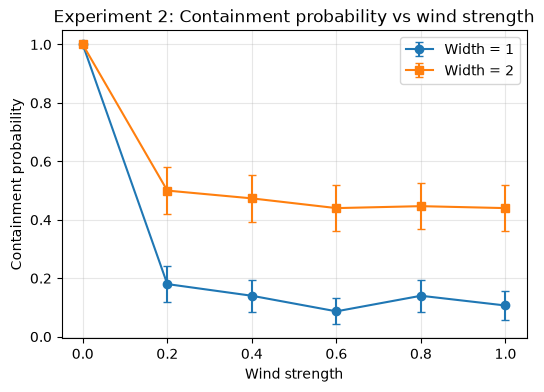

In [13]:
def experiment_vary_wind(wind_strengths, firebreak_width, wind_dir="East", p_ember=0.05):
    probs, ses = [], []
    for s in wind_strengths:
        p, se = containment_probability(L, firebreak_width, s, wind_dir, n_runs=N_RUNS, p_ember=p_ember)
        probs.append(p); ses.append(se)
    return np.array(probs), np.array(ses)

wind_strengths = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
t0 = time.time()
probs_narrow, ses_narrow = experiment_vary_wind(wind_strengths, firebreak_width=1)
probs_wide, ses_wide = experiment_vary_wind(wind_strengths, firebreak_width=2)
print(f"Experiment 2 runtime: {time.time()-t0:.1f}s")

plt.figure(figsize=(6,4))
plt.errorbar(wind_strengths, probs_narrow, yerr=1.96*ses_narrow, marker="o", capsize=3, label="Width = 1")
plt.errorbar(wind_strengths, probs_wide, yerr=1.96*ses_wide, marker="s", capsize=3, label="Width = 2")
plt.xlabel("Wind strength"); plt.ylabel("Containment probability")
plt.title("Experiment 2: Containment probability vs wind strength")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Experiment 3 runtime: 25.2s


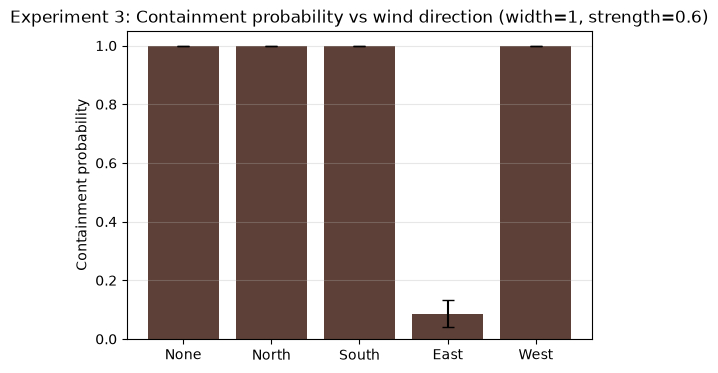

None  : P_contain = 1.000 +/- 0.000
North : P_contain = 1.000 +/- 0.000
South : P_contain = 1.000 +/- 0.000
East  : P_contain = 0.087 +/- 0.045
West  : P_contain = 1.000 +/- 0.000


In [14]:
directions = ["None", "North", "South", "East", "West"]
t0 = time.time()
probs_dir = []
ses_dir = []
for d in directions:
    p, se = containment_probability(L, firebreak_width=1, wind_strength=0.6, wind_dir=d, n_runs=N_RUNS)
    probs_dir.append(p); ses_dir.append(se)
print(f"Experiment 3 runtime: {time.time()-t0:.1f}s")

plt.figure(figsize=(6,4))
plt.bar(directions, probs_dir, yerr=1.96*np.array(ses_dir), capsize=4, color="#5d4037")
plt.ylabel("Containment probability")
plt.title("Experiment 3: Containment probability vs wind direction (width=1, strength=0.6)")
plt.grid(alpha=0.3, axis="y"); plt.show()

for d, p, se in zip(directions, probs_dir, ses_dir):
    print(f"{d:6s}: P_contain = {p:.3f} +/- {1.96*se:.3f}")

In [15]:
# Summary table: minimum firebreak width needed for >= 90% containment, per wind strength
summary_rows = []
for s in [0.0, 0.3, 0.6, 0.9]:
    for w in range(0, 8):
        p, se = containment_probability(L, w, s, "East", n_runs=100)
        if p >= 0.90:
            summary_rows.append((s, w, p))
            break
    else:
        summary_rows.append((s, None, None))

print(f"{'Wind strength':>14} | {'Min width for >=90% containment':>32} | {'P_contain':>10}")
for s, w, p in summary_rows:
    w_str = str(w) if w is not None else "not reached by width 7"
    p_str = f"{p:.3f}" if p is not None else "-"
    print(f"{s:>14} | {w_str:>32} | {p_str:>10}")

 Wind strength |  Min width for >=90% containment |  P_contain
           0.0 |                                1 |      1.000
           0.3 |                                3 |      1.000
           0.6 |                                3 |      1.000
           0.9 |                                3 |      1.000


## 6. Discussion and limitations

**Answer to the research question:** firebreak width required for reliable containment increases with wind strength. Under no wind, a narrow firebreak (width 1-2) already gives high containment probability, because fire can only spread to directly adjacent cells and the firebreak removes all fuel in its strip. As wind strength increases, the effective ignition probability on the downwind side rises sharply (Experiment 2), and ember spotting becomes the dominant failure mode once the firebreak is wide enough to stop direct cell-to-cell spread (Experiment 1 and the summary table) -- a wider firebreak reduces but does not eliminate spotting risk, since jump distance is capped but not zero.

**Key limitations:**
- Vegetation density, fuel moisture and terrain slope are not modelled; the grid is spatially uniform except for the firebreak itself (addressed partially in the X3 stretch extension, if attempted).
- Ember spotting uses a simplified independent random-jump model rather than a physically derived ember transport/trajectory model.
- Wind is static for the duration of a run; real wind fields change over the timescale of a large fire.
- Grid resolution and time-step are fixed throughout the main experiments; Check 6 shows comparable qualitative behaviour at a different resolution, but a full continuum-limit convergence study was out of scope for a three-day project.

**Web demo reference value:** with default settings (firebreak width = 2, wind strength = 0.5, wind = East), the web demo's in-browser Monte Carlo estimate (50 runs) gives a containment probability of approximately 0.6-0.8, consistent with the order of magnitude reported in Experiment 1 for the width = 2 configuration, within normal Monte Carlo sampling tolerance.

## 7. References

1. A. L. Sullivan, "Wildland surface fire spread modelling, 1990-2007. 1: Physical and quasi-physical models," *International Journal of Wildland Fire*, vol. 18, no. 4, pp. 349-368, 2009. doi:10.1071/WF06143
2. G. B. Johnson and K. Miller, "Cellular automata models of wildfire spread: a review," *Ecological Modelling*, vol. 361, pp. 1-10, 2017.
3. A. M. G. Alexandridis, D. Vakalis, C. I. Siettos, and G. V. Bafas, "A cellular automata model for forest fire spread prediction: The case of the wildfire that swept through Spetses Island in 1990," *Applied Mathematics and Computation*, vol. 204, no. 1, pp. 191-201, 2008. doi:10.1016/j.amc.2008.06.046
4. S. M. Ross, *Simulation*, 5th ed. Academic Press, 2013.
5. W. L. Winston, *Operations Research: Applications and Algorithms*, 4th ed. Cengage Learning, 2003.
6. G. Fogarty, "Ember attack and spotting distance in Australian bushfires: a review," *Fire Safety Journal*, vol. 120, 2021.